# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm

## 1. Setup

In [1]:
%pip install -q scikit-image scikit-learn matplotlib seaborn pandas tabulate joblib

In [2]:
import os, time, random, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import cv2
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUT_DIR = "."
os.makedirs(OUT_DIR, exist_ok=True)

try:
    import cupy as xp
    GPU = xp.cuda.runtime.getDeviceCount() > 0
except Exception:
    GPU = False
if not GPU:
    import numpy as xp

def to_np(a):
    return xp.asnumpy(a) if GPU else a

def free_gpu():
    if GPU:
        xp.get_default_memory_pool().free_all_blocks()

print("GPU available:", GPU)

def save_fig(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=200, bbox_inches="tight")

GPU available: True


## 2. Configuration

In [3]:
IMG_SIZE = 128
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")
C_GRID = [1, 10, 100]
GAMMA_MULTS = [0.5, 1.0, 2.0]
N_THREADS = max(1, os.cpu_count() or 1)

GA_FIT_TRAIN = 3000
GA_ALPHA = 0.1
GA_MIN_FEATURES = 50
GA_SETTINGS = {
    "GA-1": dict(pop_size=20, generations=20, p_mut=0.005, p_cross=0.8, elite=2, tourn=3),
    "GA-2": dict(pop_size=30, generations=20, p_mut=0.02, p_cross=0.8, elite=2, tourn=3),
}

DATASET_NAME = "BloodMNIST (MedMNIST+, 128x128)"
DATA_URL = "https://zenodo.org/records/10519652/files/bloodmnist_128.npz?download=1"
DATA_DIR = os.path.join(os.path.expanduser("~"), "medmnist_data")
DATA_PATH = os.path.join(DATA_DIR, "bloodmnist_128.npz")
CLASS_NAMES = ["basophil", "eosinophil", "erythroblast", "immature granulocyte",
               "lymphocyte", "monocyte", "neutrophil", "platelet"]
N_CLASSES = len(CLASS_NAMES)

## 3. Dataset (Task 1)

In [4]:
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

data = np.load(DATA_PATH)
X_train_img, y_train = data["train_images"], data["train_labels"].ravel()
X_val_img, y_val = data["val_images"], data["val_labels"].ravel()
X_test_img, y_test = data["test_images"], data["test_labels"].ravel()

print("Train:", X_train_img.shape, "| Val:", X_val_img.shape, "| Test:", X_test_img.shape)

Train: (11959, 128, 128, 3) | Val: (1712, 128, 128, 3) | Test: (3421, 128, 128, 3)


## 4. Preprocessing and Data Splits (Task 2)

In [5]:
split_df = pd.DataFrame({
    "Train": np.bincount(y_train, minlength=N_CLASSES),
    "Validation": np.bincount(y_val, minlength=N_CLASSES),
    "Test": np.bincount(y_test, minlength=N_CLASSES),
}, index=CLASS_NAMES)
split_df.loc["Total"] = split_df.sum()
display(split_df)
print(split_df.to_markdown())

,Train,Validation,Test
basophil,852,122,244
eosinophil,2181,312,624
erythroblast,1085,155,311
immature granulocyte,2026,290,579
lymphocyte,849,122,243
monocyte,993,143,284
neutrophil,2330,333,666
platelet,1643,235,470
Total,11959,1712,3421


|                      |   Train |   Validation |   Test |
|:---------------------|--------:|-------------:|-------:|
| basophil             |     852 |          122 |    244 |
| eosinophil           |    2181 |          312 |    624 |
| erythroblast         |    1085 |          155 |    311 |
| immature granulocyte |    2026 |          290 |    579 |
| lymphocyte           |     849 |          122 |    243 |
| monocyte             |     993 |          143 |    284 |
| neutrophil           |    2330 |          333 |    666 |
| platelet             |    1643 |          235 |    470 |
| Total                |   11959 |         1712 |   3421 |


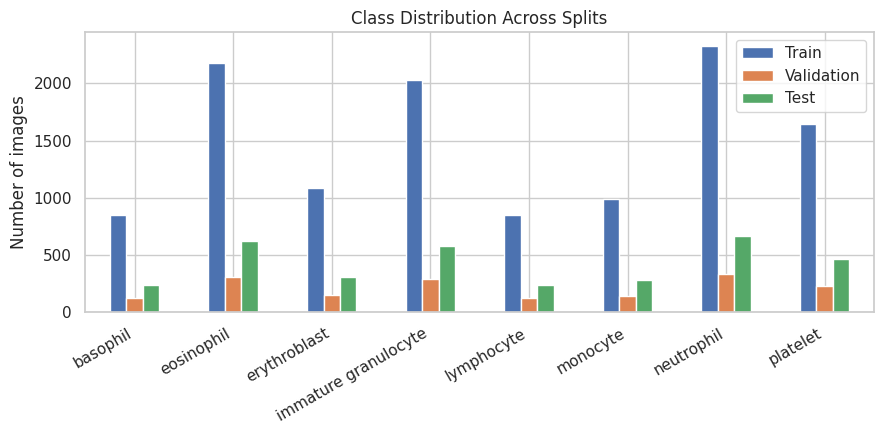

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
split_df.drop(index="Total").plot(kind="bar", ax=ax)
ax.set_title("Class Distribution Across Splits")
ax.set_ylabel("Number of images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
save_fig("class_distribution.png")
plt.show()

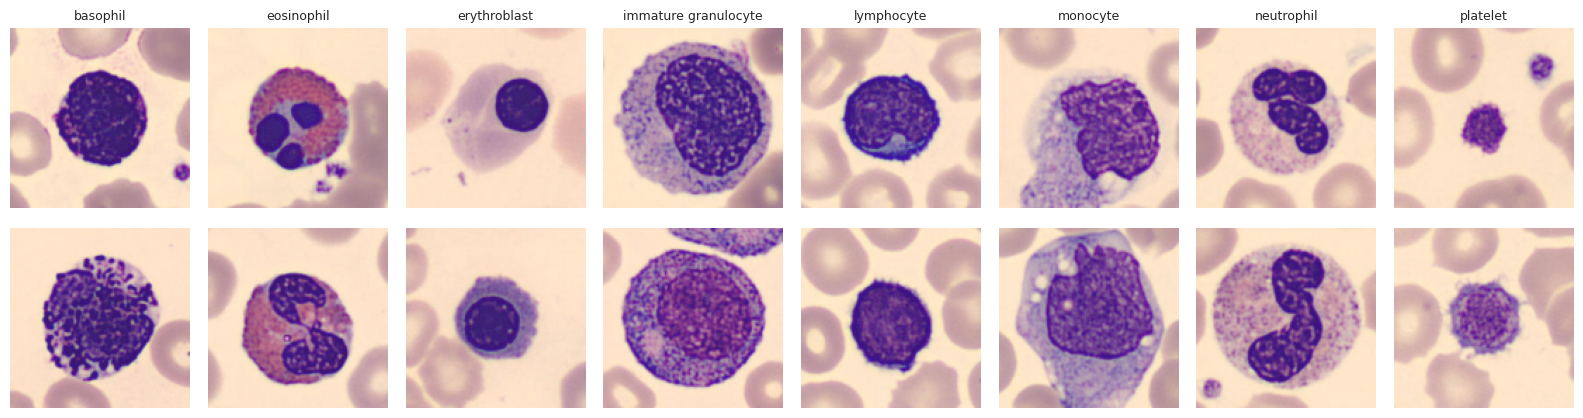

In [7]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for c in range(N_CLASSES):
    idx = np.flatnonzero(y_train == c)[:2]
    for r, i in enumerate(idx):
        axes[r, c].imshow(X_train_img[i])
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(CLASS_NAMES[c], fontsize=9)
plt.tight_layout()
save_fig("dataset_samples.png")
plt.show()

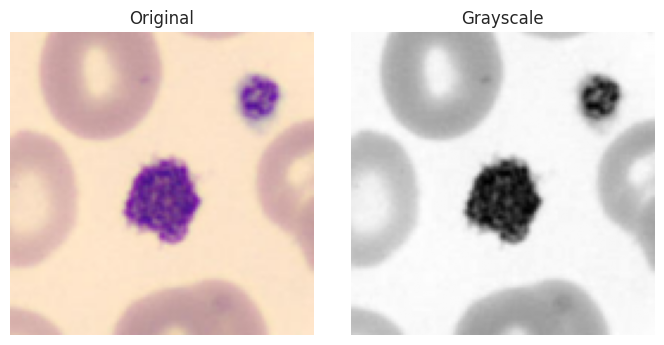

In [8]:
GRAY_W = np.array([0.299, 0.587, 0.114], dtype=np.float32)

def preprocess(img):
    return np.dot(img[..., :3].astype(np.float32), GRAY_W) / 255.0

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(X_train_img[0]); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(preprocess(X_train_img[0]), cmap="gray"); axes[1].set_title("Grayscale"); axes[1].axis("off")
plt.tight_layout()
save_fig("preprocessing_example.png")
plt.show()

## 5. HOG Feature Extraction (Task 4)

In [9]:
hog_cv = cv2.HOGDescriptor((IMG_SIZE, IMG_SIZE), (16, 16), (8, 8), (8, 8), HOG_PARAMS["orientations"])

def hog_one(img):
    return hog_cv.compute(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)).ravel()

def extract_hog(images):
    return np.asarray([hog_one(im) for im in images], dtype=np.float32)

t0 = time.time()
X_train = extract_hog(X_train_img)
X_val = extract_hog(X_val_img)
X_test = extract_hog(X_test_img)
hog_time = time.time() - t0

N_FEATURES = X_train.shape[1]
N_BLOCKS = IMG_SIZE // HOG_PARAMS["pixels_per_cell"][0] - 1
print("HOG feature dimension:", N_FEATURES)
print("HOG extraction time (s):", round(hog_time, 2))

HOG feature dimension: 8100
HOG extraction time (s): 7.36


In [10]:
scaler = StandardScaler().fit(X_train)
Xs_train = scaler.transform(X_train).astype(np.float32)
Xs_val = scaler.transform(X_val).astype(np.float32)
Xs_test = scaler.transform(X_test).astype(np.float32)

Ttr = xp.asarray(Xs_train)
Tva = xp.asarray(Xs_val)
Tte = xp.asarray(Xs_test)

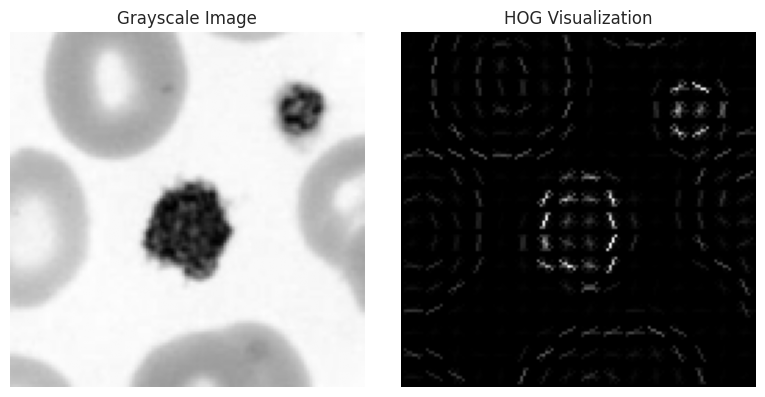

In [11]:
img0 = preprocess(X_train_img[0])
_, hog_img = hog(img0, visualize=True, **HOG_PARAMS)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img0, cmap="gray"); axes[0].set_title("Grayscale Image"); axes[0].axis("off")
axes[1].imshow(hog_img, cmap="gray"); axes[1].set_title("HOG Visualization"); axes[1].axis("off")
plt.tight_layout()
save_fig("hog_visualization.png")
plt.show()

## 6. Evaluation Utilities

In [12]:
def specificity_macro(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = cm.sum() - (tp + fp + fn)
    return np.mean(tn / (tn + fp))

def full_metrics(y_true, y_pred):
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (Macro, %)": precision_score(y_true, y_pred, average="macro", zero_division=0) * 100,
        "Recall (Macro, %)": recall_score(y_true, y_pred, average="macro", zero_division=0) * 100,
        "Macro-F1 (%)": f1_score(y_true, y_pred, average="macro", zero_division=0) * 100,
        "Weighted-F1 (%)": f1_score(y_true, y_pred, average="weighted", zero_division=0) * 100,
        "Balanced accuracy (%)": balanced_accuracy_score(y_true, y_pred) * 100,
        "Specificity (Macro, %)": specificity_macro(y_true, y_pred) * 100,
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
        "Matthews correlation coefficient": matthews_corrcoef(y_true, y_pred),
    }

def sq_dist(P, Q):
    d = (P * P).sum(axis=1)[:, None] + (Q * Q).sum(axis=1)[None, :] - 2.0 * (P @ Q.T)
    return xp.maximum(d, 0)

def scale_gamma(A):
    return 1.0 / (A.shape[1] * float(A.var()))

def rbf_np(D, gamma):
    return to_np(xp.exp(-gamma * D).astype(np.float64))

def views(idx=None):
    if idx is None:
        return Ttr, Tva, Tte
    t = xp.asarray(idx)
    return Ttr[:, t], Tva[:, t], Tte[:, t]

def svm_fit_eval(Ktr, ytr, Kva, yva, C):
    t0 = time.time()
    clf = SVC(kernel="precomputed", C=C, random_state=SEED).fit(Ktr, ytr)
    fit_time = time.time() - t0
    return f1_score(yva, clf.predict(Kva), average="macro"), fit_time

def tune_svm(A, ytr, B, yva):
    g0 = scale_gamma(A)
    D_tr, D_va = sq_dist(A, A), sq_dist(B, A)
    rows = []
    for m in GAMMA_MULTS:
        g = g0 * m
        Ktr, Kva = rbf_np(D_tr, g), rbf_np(D_va, g)
        res = Parallel(n_jobs=N_THREADS, prefer="threads")(
            delayed(svm_fit_eval)(Ktr, ytr, Kva, yva, C) for C in C_GRID)
        for C, r in zip(C_GRID, res):
            rows.append({"C": C, "gamma_mult": m, "gamma": g, "Val Macro-F1": r[0], "Fit time (s)": r[1]})
        del Ktr, Kva
    del D_tr, D_va
    free_gpu()
    grid = pd.DataFrame(rows)
    best = grid.loc[grid["Val Macro-F1"].idxmax()]
    return {"C": float(best["C"]), "gamma": float(best["gamma"]), "gamma_mult": float(best["gamma_mult"])}, grid

def train_final(A, ytr, params):
    t0 = time.time()
    Ktr = rbf_np(sq_dist(A, A), params["gamma"])
    clf = SVC(kernel="precomputed", C=params["C"], random_state=SEED).fit(Ktr, ytr)
    free_gpu()
    return clf, time.time() - t0

def predict_svm(clf, A, B, params):
    t0 = time.time()
    pred = clf.predict(rbf_np(sq_dist(B, A), params["gamma"]))
    free_gpu()
    return pred, time.time() - t0

## 7. Baseline HOG + SVM (Task 3)

In [13]:
t0 = time.time()
A_base, B_base, T_base = views()
base_params, base_grid = tune_svm(A_base, y_train, B_base, y_val)
base_tune_time = time.time() - t0
display(base_grid)
print("Best baseline params:", base_params)

base_clf, base_train_time = train_final(A_base, y_train, base_params)
base_val_pred, _ = predict_svm(base_clf, A_base, B_base, base_params)
base_val_f1 = f1_score(y_val, base_val_pred, average="macro")
print("Baseline validation macro-F1:", round(base_val_f1, 4))
print("Baseline training time (s):", round(base_train_time, 2))

,C,gamma_mult,gamma,Val Macro-F1,Fit time (s)
0,1,0.5,0.000062,0.795304,3.133000
1,10,0.5,0.000062,0.823748,5.093945
2,100,0.5,0.000062,0.823748,3.840643
3,1,1.0,0.000123,0.814485,4.126595
4,10,1.0,0.000123,0.828687,5.264809
5,100,1.0,0.000123,0.828687,3.494701
6,1,2.0,0.000247,0.756641,6.527082
7,10,2.0,0.000247,0.778197,6.858206
8,100,2.0,0.000247,0.778197,4.340432


Best baseline params: {'C': 10.0, 'gamma': 0.00012346091107595585, 'gamma_mult': 1.0}
Baseline validation macro-F1: 0.8287
Baseline training time (s): 4.12


## 8. Genetic Algorithm Implementation (Task 5)

In [14]:
def fitness_eval(mask, Xtr, ytr, Xva, yva, C, gmult, alpha):
    idx = np.flatnonzero(mask)
    if idx.size < GA_MIN_FEATURES:
        return -1.0, 0.0
    t = xp.asarray(idx)
    A, B = Xtr[:, t], Xva[:, t]
    g = scale_gamma(A) * gmult
    Ktr = rbf_np(sq_dist(A, A), g)
    Kva = rbf_np(sq_dist(B, A), g)
    clf = SVC(kernel="precomputed", C=C, random_state=SEED).fit(Ktr, ytr)
    f1 = f1_score(yva, clf.predict(Kva), average="macro")
    return f1 - alpha * idx.size / mask.size, f1

def init_population(rng, pop_size, n_features):
    densities = rng.uniform(0.1, 0.6, size=(pop_size, 1))
    return rng.random((pop_size, n_features)) < densities

def tournament_select(rng, pop, fit, k):
    cand = rng.integers(0, len(pop), size=k)
    return pop[cand[np.argmax(fit[cand])]]

def uniform_crossover(rng, p1, p2):
    m = rng.random(p1.size) < 0.5
    return np.where(m, p1, p2), np.where(m, p2, p1)

def mutate(rng, chrom, p_mut):
    return np.logical_xor(chrom, rng.random(chrom.size) < p_mut)

def run_ga(Xtr, ytr, Xva, yva, C, gmult, alpha, pop_size, generations, p_mut, p_cross, elite, tourn, seed):
    rng = np.random.default_rng(seed)
    n_features = Xtr.shape[1]
    pop = init_population(rng, pop_size, n_features)
    cache, history = {}, []

    def evaluate_population(population):
        keys = [np.packbits(c).tobytes() for c in population]
        todo = [i for i, k in enumerate(keys) if k not in cache]
        out = Parallel(n_jobs=N_THREADS, prefer="threads")(
            delayed(fitness_eval)(population[i], Xtr, ytr, Xva, yva, C, gmult, alpha) for i in todo)
        for i, r in zip(todo, out):
            cache[keys[i]] = r
        free_gpu()
        return np.array([cache[k] for k in keys])

    for g in range(generations + 1):
        res = evaluate_population(pop)
        fit, f1 = res[:, 0], res[:, 1]
        b = int(np.argmax(fit))
        history.append(dict(generation=g, best_fitness=fit[b], mean_fitness=fit.mean(),
                            best_val_f1=f1[b], best_n_features=int(pop[b].sum()),
                            mean_n_features=float(pop.sum(axis=1).mean())))
        print(f"Gen {g:02d} | best fitness {fit[b]:.4f} | best val F1 {f1[b]:.4f} | "
              f"features {int(pop[b].sum())} | mean fitness {fit.mean():.4f}")
        if g == generations:
            break
        order = np.argsort(-fit)
        new_pop = [pop[i].copy() for i in order[:elite]]
        while len(new_pop) < pop_size:
            p1 = tournament_select(rng, pop, fit, tourn)
            p2 = tournament_select(rng, pop, fit, tourn)
            if rng.random() < p_cross:
                c1, c2 = uniform_crossover(rng, p1, p2)
            else:
                c1, c2 = p1.copy(), p2.copy()
            new_pop.append(mutate(rng, c1, p_mut))
            if len(new_pop) < pop_size:
                new_pop.append(mutate(rng, c2, p_mut))
        pop = np.array(new_pop)

    best = int(np.argmax(fit))
    return pop[best].copy(), float(fit[best]), float(f1[best]), pd.DataFrame(history)

## 9. GA Feature Selection (Task 6)

In [15]:
sub_idx, _ = train_test_split(np.arange(len(y_train)), train_size=min(GA_FIT_TRAIN, len(y_train) - N_CLASSES),
                              stratify=y_train, random_state=SEED)
Tga, yga_train = Ttr[xp.asarray(sub_idx)], y_train[sub_idx]
print("GA fitness training subset:", Tga.shape)

GA fitness training subset: (3000, 8100)


In [16]:
ga_results = {}
for name, cfg in GA_SETTINGS.items():
    print("=" * 20, name, cfg, "=" * 20)
    t0 = time.time()
    mask, fit, f1, hist = run_ga(Tga, yga_train, Tva, y_val, base_params["C"],
                                 base_params["gamma_mult"], GA_ALPHA, seed=SEED, **cfg)
    ga_results[name] = dict(mask=mask, fitness=fit, val_f1=f1, history=hist,
                            time=time.time() - t0, n_features=int(mask.sum()), cfg=cfg)
    print(f"{name} finished in {ga_results[name]['time']:.1f}s with {int(mask.sum())} features")

==================== GA-1 {'pop_size': 20, 'generations': 20, 'p_mut': 0.005, 'p_cross': 0.8, 'elite': 2, 'tourn': 3} ====================
Gen 00 | best fitness 0.7025 | best val F1 0.7342 | features 2567 | mean fitness 0.6870
Gen 01 | best fitness 0.7025 | best val F1 0.7342 | features 2567 | mean fitness 0.6899
Gen 02 | best fitness 0.7031 | best val F1 0.7289 | features 2093 | mean fitness 0.6935
Gen 03 | best fitness 0.7031 | best val F1 0.7289 | features 2093 | mean fitness 0.6943
Gen 04 | best fitness 0.7060 | best val F1 0.7351 | features 2359 | mean fitness 0.6969
Gen 05 | best fitness 0.7060 | best val F1 0.7351 | features 2359 | mean fitness 0.6988
Gen 06 | best fitness 0.7060 | best val F1 0.7351 | features 2359 | mean fitness 0.7011
Gen 07 | best fitness 0.7090 | best val F1 0.7385 | features 2386 | mean fitness 0.6990
Gen 08 | best fitness 0.7101 | best val F1 0.7381 | features 2263 | mean fitness 0.7028
Gen 09 | best fitness 0.7132 | best val F1 0.7426 | features 2378 | m

In [17]:
ga_table = pd.DataFrame([{
    "Setting": n, "Population": r["cfg"]["pop_size"], "Generations": r["cfg"]["generations"],
    "Mutation prob.": r["cfg"]["p_mut"], "Crossover prob.": r["cfg"]["p_cross"],
    "Best fitness": r["fitness"], "Val Macro-F1 (GA subset)": r["val_f1"],
    "Selected features": r["n_features"], "Reduction (%)": 100 * (1 - r["n_features"] / N_FEATURES),
    "GA time (s)": r["time"]} for n, r in ga_results.items()])
display(ga_table)
print(ga_table.to_markdown(index=False))

best_setting = max(ga_results, key=lambda n: ga_results[n]["fitness"])
ga_mask = ga_results[best_setting]["mask"]
ga_idx = np.flatnonzero(ga_mask)
print("Selected GA setting:", best_setting, "| features:", ga_idx.size)

,Setting,Population,Generations,Mutation prob.,Crossover prob.,Best fitness,Val Macro-F1 (GA subset),Selected features,Reduction (%),GA time (s)
0,GA-1,20,20,0.005,0.8,0.724855,0.756028,2525,68.82716,114.983890
1,GA-2,30,20,0.020,0.8,0.717098,0.755012,3071,62.08642,190.371667


| Setting   |   Population |   Generations |   Mutation prob. |   Crossover prob. |   Best fitness |   Val Macro-F1 (GA subset) |   Selected features |   Reduction (%) |   GA time (s) |
|:----------|-------------:|--------------:|-----------------:|------------------:|---------------:|---------------------------:|--------------------:|----------------:|--------------:|
| GA-1      |           20 |            20 |            0.005 |               0.8 |       0.724855 |                   0.756028 |                2525 |         68.8272 |       114.984 |
| GA-2      |           30 |            20 |            0.02  |               0.8 |       0.717098 |                   0.755012 |                3071 |         62.0864 |       190.372 |
Selected GA setting: GA-1 | features: 2525


## 10. GA Fitness and Feature Count Plots (Task 9)

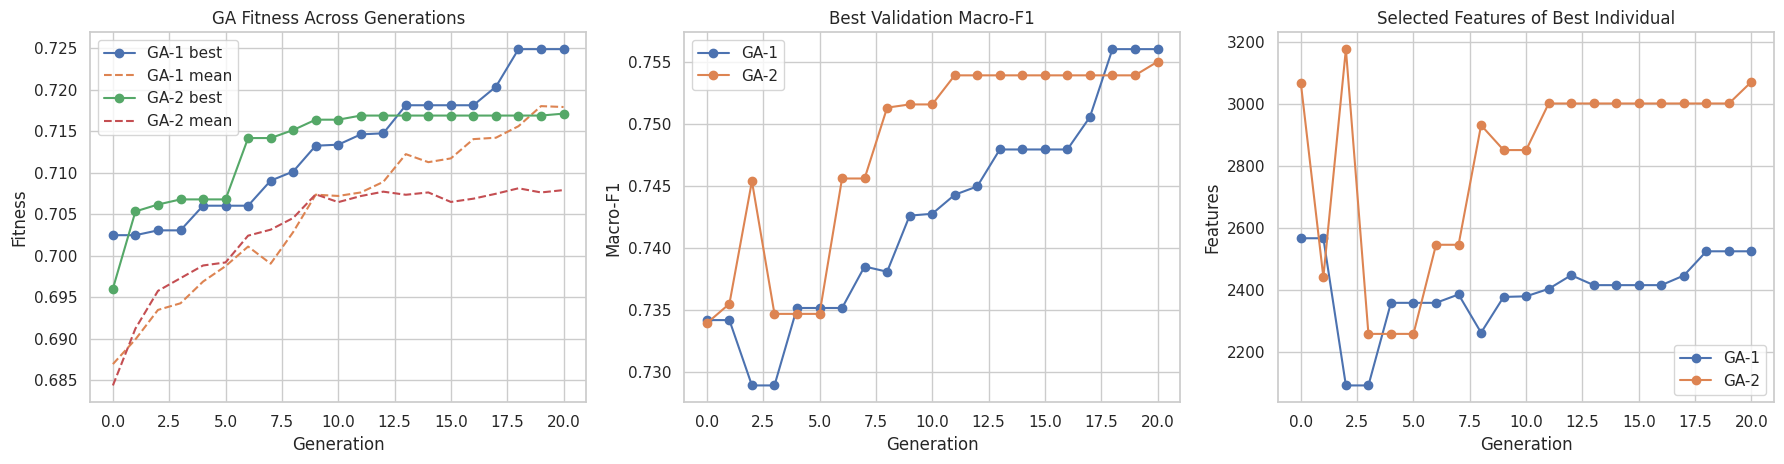

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for name, r in ga_results.items():
    h = r["history"]
    axes[0].plot(h["generation"], h["best_fitness"], marker="o", label=f"{name} best")
    axes[0].plot(h["generation"], h["mean_fitness"], linestyle="--", label=f"{name} mean")
    axes[1].plot(h["generation"], h["best_val_f1"], marker="o", label=name)
    axes[2].plot(h["generation"], h["best_n_features"], marker="o", label=name)
axes[0].set_title("GA Fitness Across Generations"); axes[0].set_xlabel("Generation"); axes[0].set_ylabel("Fitness")
axes[1].set_title("Best Validation Macro-F1"); axes[1].set_xlabel("Generation"); axes[1].set_ylabel("Macro-F1")
axes[2].set_title("Selected Features of Best Individual"); axes[2].set_xlabel("Generation"); axes[2].set_ylabel("Features")
for a in axes:
    a.legend()
plt.tight_layout()
save_fig("ga_fitness_curves.png")
plt.show()

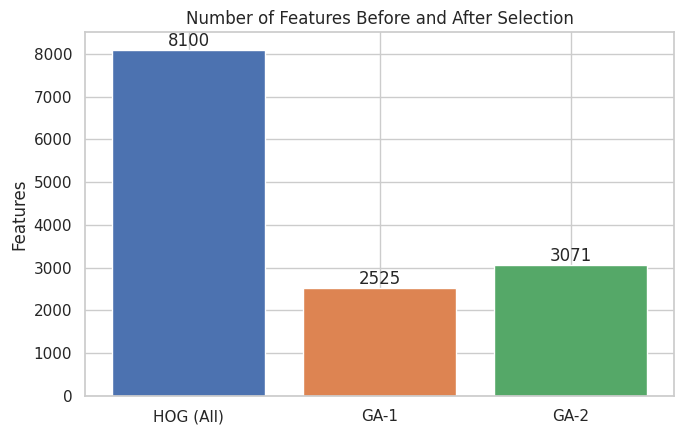

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))
labels = ["HOG (All)"] + list(ga_results.keys())
counts = [N_FEATURES] + [r["n_features"] for r in ga_results.values()]
bars = ax.bar(labels, counts, color=sns.color_palette("deep", len(labels)))
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, c, str(c), ha="center", va="bottom")
ax.set_title("Number of Features Before and After Selection")
ax.set_ylabel("Features")
plt.tight_layout()
save_fig("feature_count_comparison.png")
plt.show()

## 11. GA-HOG + SVM Training (Task 7)

In [20]:
A_ga, B_ga, T_ga = views(ga_idx)

t0 = time.time()
ga_params, ga_grid = tune_svm(A_ga, y_train, B_ga, y_val)
ga_tune_time = time.time() - t0
display(ga_grid)
print("Best GA-HOG params:", ga_params)

ga_clf, ga_train_time = train_final(A_ga, y_train, ga_params)
ga_val_pred, _ = predict_svm(ga_clf, A_ga, B_ga, ga_params)
ga_val_f1 = f1_score(y_val, ga_val_pred, average="macro")
print("GA-HOG validation macro-F1:", round(ga_val_f1, 4))
print("GA-HOG training time (s):", round(ga_train_time, 2))

,C,gamma_mult,gamma,Val Macro-F1,Fit time (s)
0,1,0.5,0.000198,0.787547,3.278547
1,10,0.5,0.000198,0.816526,6.104908
2,100,0.5,0.000198,0.816336,4.404460
3,1,1.0,0.000396,0.800992,4.013845
4,10,1.0,0.000396,0.824533,5.277756
5,100,1.0,0.000396,0.824533,3.572563
6,1,2.0,0.000792,0.760230,6.674258
7,10,2.0,0.000792,0.781433,7.052482
8,100,2.0,0.000792,0.781433,4.178847


Best GA-HOG params: {'C': 10.0, 'gamma': 0.0003960417520998395, 'gamma_mult': 1.0}
GA-HOG validation macro-F1: 0.8245
GA-HOG training time (s): 3.66


## 12. Final Test Evaluation (Task 8)

In [21]:
base_pred, base_inf_time = predict_svm(base_clf, A_base, T_base, base_params)
ga_pred, ga_inf_time = predict_svm(ga_clf, A_ga, T_ga, ga_params)

base_metrics = full_metrics(y_test, base_pred)
ga_metrics = full_metrics(y_test, ga_pred)

## Table 1. Experimental Configuration and HOG Parameters

In [22]:
table1 = pd.DataFrame([
    ["Medical dataset", DATASET_NAME, DATASET_NAME],
    ["Image resolution", f"{IMG_SIZE} x {IMG_SIZE}", f"{IMG_SIZE} x {IMG_SIZE}"],
    ["HOG orientations", HOG_PARAMS["orientations"], HOG_PARAMS["orientations"]],
    ["Pixels per cell", "8 x 8", "8 x 8"],
    ["Cells per block", "2 x 2", "2 x 2"],
    ["Block normalization", HOG_PARAMS["block_norm"], HOG_PARAMS["block_norm"]],
    ["HOG feature dimension", N_FEATURES, N_FEATURES],
    ["Feature selection", "None", "Genetic Algorithm"],
    ["Features used by classifier", N_FEATURES, ga_idx.size],
    ["HOG implementation", "OpenCV HOGDescriptor", "OpenCV HOGDescriptor"],
    ["Classifier", "SVM", "SVM"],
    ["SVM kernel", "RBF (precomputed)", "RBF (precomputed)"],
    ["Hyperparameter tuning", f"Validation set (C {C_GRID}, gamma x {GAMMA_MULTS})",
     f"Validation set (C {C_GRID}, gamma x {GAMMA_MULTS})"],
    ["Selected C", base_params["C"], ga_params["C"]],
    ["Selected gamma multiplier", base_params["gamma_mult"], ga_params["gamma_mult"]],
    ["Data split", f"Fixed ({len(y_train)} / {len(y_val)} / {len(y_test)})",
     f"Fixed ({len(y_train)} / {len(y_val)} / {len(y_test)})"],
    ["Random seed", SEED, SEED],
], columns=["Parameter", "Baseline: HOG + SVM", "Proposed: GA-HOG + SVM"])
display(table1)
print(table1.to_markdown(index=False))

,Parameter,Baseline: HOG + SVM,Proposed: GA-HOG + SVM
0,Medical dataset,"BloodMNIST (MedMNIST+, 128x128)","BloodMNIST (MedMNIST+, 128x128)"
1,Image resolution,128 x 128,128 x 128
2,HOG orientations,9,9
3,Pixels per cell,8 x 8,8 x 8
4,Cells per block,2 x 2,2 x 2
5,Block normalization,L2-Hys,L2-Hys
6,HOG feature dimension,8100,8100
7,Feature selection,None,Genetic Algorithm
8,Features used by classifier,8100,2525
9,HOG implementation,OpenCV HOGDescriptor,OpenCV HOGDescriptor


| Parameter                   | Baseline: HOG + SVM                                      | Proposed: GA-HOG + SVM                                   |
|:----------------------------|:---------------------------------------------------------|:---------------------------------------------------------|
| Medical dataset             | BloodMNIST (MedMNIST+, 128x128)                          | BloodMNIST (MedMNIST+, 128x128)                          |
| Image resolution            | 128 x 128                                                | 128 x 128                                                |
| HOG orientations            | 9                                                        | 9                                                        |
| Pixels per cell             | 8 x 8                                                    | 8 x 8                                                    |
| Cells per block             | 2 x 2                                                    | 2 x 2    

## Table 2. Main Performance Comparison (Test Set)

In [23]:
table2 = pd.DataFrame({
    "Metric": list(base_metrics.keys()),
    "HOG + SVM (Baseline)": list(base_metrics.values()),
    "GA-HOG + SVM (Proposed)": list(ga_metrics.values()),
})
table2["Improvement"] = table2["GA-HOG + SVM (Proposed)"] - table2["HOG + SVM (Baseline)"]
table2 = table2.round(4)
display(table2)
print(table2.to_markdown(index=False))

,Metric,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement
0,Accuracy (%),81.1166,79.3335,-1.7831
1,"Precision (Macro, %)",81.7464,80.6543,-1.0921
2,"Recall (Macro, %)",79.1591,77.6554,-1.5038
3,Macro-F1 (%),80.2297,78.8666,-1.3631
4,Weighted-F1 (%),80.9905,79.2244,-1.7661
5,Balanced accuracy (%),79.1591,77.6554,-1.5038
6,"Specificity (Macro, %)",97.2092,96.9345,-0.2747
7,Cohen's kappa,0.7785,0.7575,-0.0210
8,Matthews correlation coefficient,0.7789,0.7580,-0.0209


| Metric                           |   HOG + SVM (Baseline) |   GA-HOG + SVM (Proposed) |   Improvement |
|:---------------------------------|-----------------------:|--------------------------:|--------------:|
| Accuracy (%)                     |                81.1166 |                   79.3335 |       -1.7831 |
| Precision (Macro, %)             |                81.7464 |                   80.6543 |       -1.0921 |
| Recall (Macro, %)                |                79.1591 |                   77.6554 |       -1.5038 |
| Macro-F1 (%)                     |                80.2297 |                   78.8666 |       -1.3631 |
| Weighted-F1 (%)                  |                80.9905 |                   79.2244 |       -1.7661 |
| Balanced accuracy (%)            |                79.1591 |                   77.6554 |       -1.5038 |
| Specificity (Macro, %)           |                97.2092 |                   96.9345 |       -0.2747 |
| Cohen's kappa                    |          

## Table 3. Feature Count and Computational Cost

In [24]:
total_base = hog_time + base_tune_time + base_train_time
total_ga = hog_time + ga_results[best_setting]["time"] + ga_tune_time + ga_train_time
table3 = pd.DataFrame([
    ["Feature dimension", N_FEATURES, ga_idx.size],
    ["Feature reduction (%)", 0.0, 100 * (1 - ga_idx.size / N_FEATURES)],
    ["HOG extraction time (s)", hog_time, hog_time],
    ["GA selection time (s)", 0.0, ga_results[best_setting]["time"]],
    ["SVM tuning time (s)", base_tune_time, ga_tune_time],
    ["Final SVM training time (s)", base_train_time, ga_train_time],
    ["Test inference time (s)", base_inf_time, ga_inf_time],
    ["Total pipeline time (s)", total_base, total_ga],
], columns=["Item", "HOG + SVM (Baseline)", "GA-HOG + SVM (Proposed)"]).round(3)
display(table3)
print(table3.to_markdown(index=False))

,Item,HOG + SVM (Baseline),GA-HOG + SVM (Proposed)
0,Feature dimension,8100.000,2525.000
1,Feature reduction (%),0.000,68.827
2,HOG extraction time (s),7.365,7.365
3,GA selection time (s),0.000,114.984
4,SVM tuning time (s),31.160,30.200
5,Final SVM training time (s),4.123,3.665
6,Test inference time (s),0.978,0.741
7,Total pipeline time (s),42.648,156.213


| Item                        |   HOG + SVM (Baseline) |   GA-HOG + SVM (Proposed) |
|:----------------------------|-----------------------:|--------------------------:|
| Feature dimension           |               8100     |                  2525     |
| Feature reduction (%)       |                  0     |                    68.827 |
| HOG extraction time (s)     |                  7.365 |                     7.365 |
| GA selection time (s)       |                  0     |                   114.984 |
| SVM tuning time (s)         |                 31.16  |                    30.2   |
| Final SVM training time (s) |                  4.123 |                     3.665 |
| Test inference time (s)     |                  0.978 |                     0.741 |
| Total pipeline time (s)     |                 42.648 |                   156.213 |


## Table 4. GA Settings Comparison

In [25]:
display(ga_table.round(4))
print(ga_table.round(4).to_markdown(index=False))

,Setting,Population,Generations,Mutation prob.,Crossover prob.,Best fitness,Val Macro-F1 (GA subset),Selected features,Reduction (%),GA time (s)
0,GA-1,20,20,0.005,0.8,0.7249,0.756,2525,68.8272,114.9839
1,GA-2,30,20,0.020,0.8,0.7171,0.755,3071,62.0864,190.3717


| Setting   |   Population |   Generations |   Mutation prob. |   Crossover prob. |   Best fitness |   Val Macro-F1 (GA subset) |   Selected features |   Reduction (%) |   GA time (s) |
|:----------|-------------:|--------------:|-----------------:|------------------:|---------------:|---------------------------:|--------------------:|----------------:|--------------:|
| GA-1      |           20 |            20 |            0.005 |               0.8 |         0.7249 |                      0.756 |                2525 |         68.8272 |       114.984 |
| GA-2      |           30 |            20 |            0.02  |               0.8 |         0.7171 |                      0.755 |                3071 |         62.0864 |       190.372 |


## Confusion Matrices

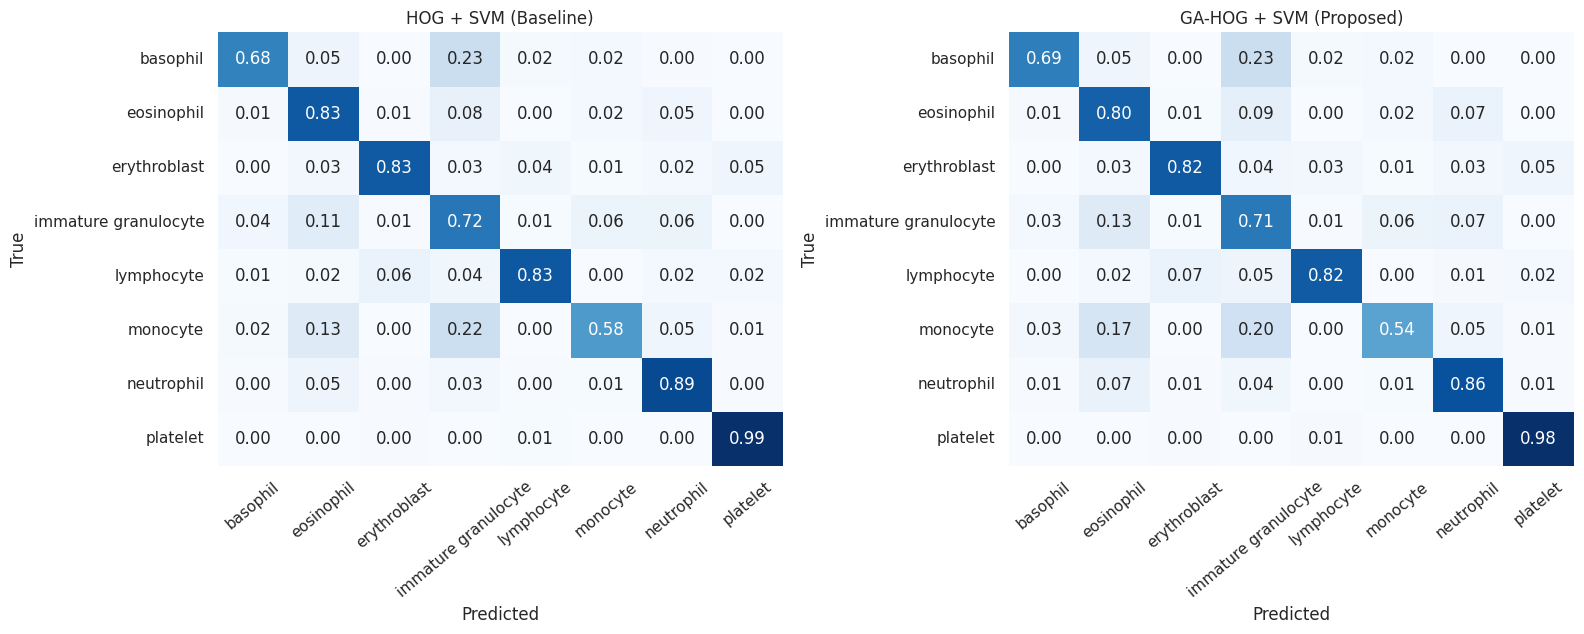

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, pred, title in zip(axes, [base_pred, ga_pred], ["HOG + SVM (Baseline)", "GA-HOG + SVM (Proposed)"]):
    cm = confusion_matrix(y_test, pred, labels=range(N_CLASSES), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=ax, cbar=False)
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
save_fig("confusion_matrices.png")
plt.show()

## Per-Class Results

,Class,Baseline F1,GA-HOG F1,Support,Difference
0,basophil,0.7366,0.7483,244.0,0.0117
1,eosinophil,0.7951,0.7559,624.0,-0.0392
2,erythroblast,0.8624,0.8548,311.0,-0.0076
3,immature granulocyte,0.6922,0.6783,579.0,-0.0139
4,lymphocyte,0.8487,0.8468,243.0,-0.0019
5,monocyte,0.6420,0.6160,284.0,-0.0260
6,neutrophil,0.8767,0.8488,666.0,-0.0279
7,platelet,0.9646,0.9604,470.0,-0.0042


| Class                |   Baseline F1 |   GA-HOG F1 |   Support |   Difference |
|:---------------------|--------------:|------------:|----------:|-------------:|
| basophil             |        0.7366 |      0.7483 |       244 |       0.0117 |
| eosinophil           |        0.7951 |      0.7559 |       624 |      -0.0392 |
| erythroblast         |        0.8624 |      0.8548 |       311 |      -0.0076 |
| immature granulocyte |        0.6922 |      0.6783 |       579 |      -0.0139 |
| lymphocyte           |        0.8487 |      0.8468 |       243 |      -0.0019 |
| monocyte             |        0.642  |      0.616  |       284 |      -0.026  |
| neutrophil           |        0.8767 |      0.8488 |       666 |      -0.0279 |
| platelet             |        0.9646 |      0.9604 |       470 |      -0.0042 |


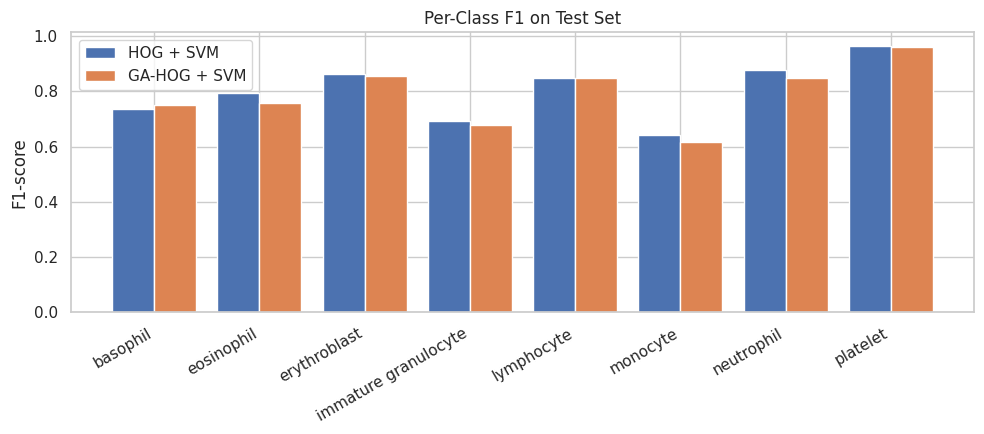

In [27]:
rep_base = classification_report(y_test, base_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
rep_ga = classification_report(y_test, ga_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
per_class = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Baseline F1": [rep_base[c]["f1-score"] for c in CLASS_NAMES],
    "GA-HOG F1": [rep_ga[c]["f1-score"] for c in CLASS_NAMES],
    "Support": [rep_base[c]["support"] for c in CLASS_NAMES],
}).round(4)
per_class["Difference"] = (per_class["GA-HOG F1"] - per_class["Baseline F1"]).round(4)
display(per_class)
print(per_class.to_markdown(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(N_CLASSES)
ax.bar(x - 0.2, per_class["Baseline F1"], 0.4, label="HOG + SVM")
ax.bar(x + 0.2, per_class["GA-HOG F1"], 0.4, label="GA-HOG + SVM")
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.set_ylabel("F1-score"); ax.set_title("Per-Class F1 on Test Set"); ax.legend()
plt.tight_layout()
save_fig("per_class_f1.png")
plt.show()

## Metric Comparison Plot

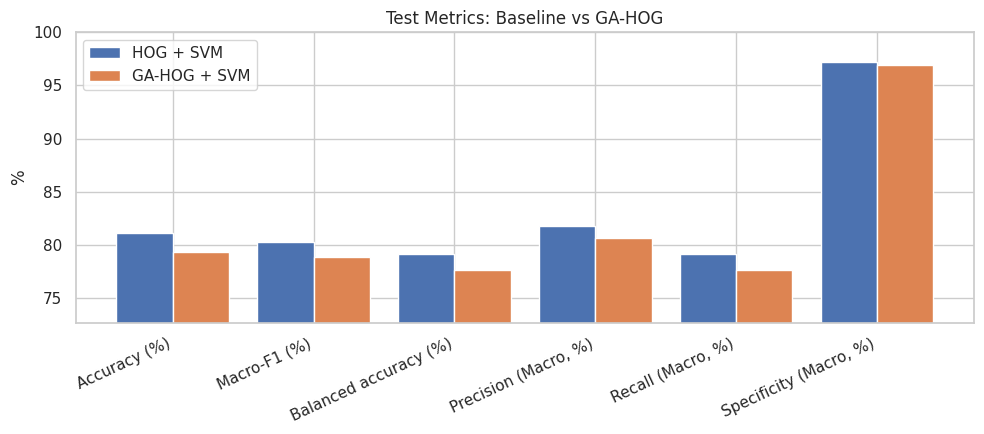

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.5))
keys = ["Accuracy (%)", "Macro-F1 (%)", "Balanced accuracy (%)", "Precision (Macro, %)", "Recall (Macro, %)", "Specificity (Macro, %)"]
x = np.arange(len(keys))
ax.bar(x - 0.2, [base_metrics[k] for k in keys], 0.4, label="HOG + SVM")
ax.bar(x + 0.2, [ga_metrics[k] for k in keys], 0.4, label="GA-HOG + SVM")
ax.set_xticks(x); ax.set_xticklabels(keys, rotation=25, ha="right")
ax.set_ylim(min(min(base_metrics[k], ga_metrics[k]) for k in keys) - 5, 100)
ax.set_ylabel("%"); ax.set_title("Test Metrics: Baseline vs GA-HOG"); ax.legend()
plt.tight_layout()
save_fig("metric_comparison.png")
plt.show()

## Bonus 1. GA vs Random Selection vs ANOVA F-test Selection

,Metric,All HOG (8100),Random (2525),ANOVA F-test (2525),GA (2525)
0,Accuracy (%),81.1166,79.1581,80.3566,79.3335
1,"Precision (Macro, %)",81.7464,80.1642,80.5025,80.6543
2,"Recall (Macro, %)",79.1591,77.3106,78.1846,77.6554
3,Macro-F1 (%),80.2297,78.4382,79.0676,78.8666
4,Weighted-F1 (%),80.9905,79.0292,80.1124,79.2244
5,Balanced accuracy (%),79.1591,77.3106,78.1846,77.6554
6,"Specificity (Macro, %)",97.2092,96.9130,97.1017,96.9345
7,Cohen's kappa,0.7785,0.7554,0.7696,0.7575
8,Matthews correlation coefficient,0.7789,0.7560,0.7701,0.7580


| Metric                           |   All HOG (8100) |   Random (2525) |   ANOVA F-test (2525) |   GA (2525) |
|:---------------------------------|-----------------:|----------------:|----------------------:|------------:|
| Accuracy (%)                     |          81.1166 |         79.1581 |               80.3566 |     79.3335 |
| Precision (Macro, %)             |          81.7464 |         80.1642 |               80.5025 |     80.6543 |
| Recall (Macro, %)                |          79.1591 |         77.3106 |               78.1846 |     77.6554 |
| Macro-F1 (%)                     |          80.2297 |         78.4382 |               79.0676 |     78.8666 |
| Weighted-F1 (%)                  |          80.9905 |         79.0292 |               80.1124 |     79.2244 |
| Balanced accuracy (%)            |          79.1591 |         77.3106 |               78.1846 |     77.6554 |
| Specificity (Macro, %)           |          97.2092 |         96.913  |               97.1017 |     96

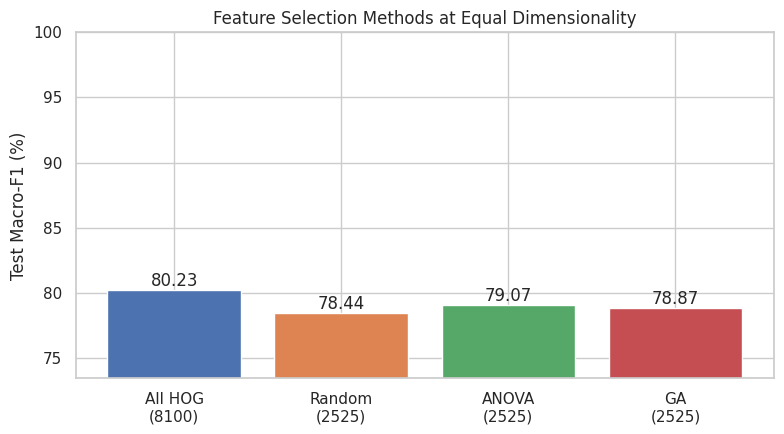

In [29]:
def run_subset(idx):
    A, B, T = views(idx)
    params, _ = tune_svm(A, y_train, B, y_val)
    clf, tt = train_final(A, y_train, params)
    pred, _ = predict_svm(clf, A, T, params)
    return pred, full_metrics(y_test, pred), tt

k = ga_idx.size
rand_idx = np.sort(np.random.default_rng(SEED).choice(N_FEATURES, k, replace=False))
kbest_idx = np.flatnonzero(SelectKBest(f_classif, k=k).fit(Xs_train, y_train).get_support())

rand_pred, rand_metrics, rand_time = run_subset(rand_idx)
kbest_pred, kbest_metrics, kbest_time = run_subset(kbest_idx)

bonus1 = pd.DataFrame({
    "Metric": list(base_metrics.keys()),
    f"All HOG ({N_FEATURES})": list(base_metrics.values()),
    f"Random ({k})": list(rand_metrics.values()),
    f"ANOVA F-test ({k})": list(kbest_metrics.values()),
    f"GA ({k})": list(ga_metrics.values()),
}).round(4)
display(bonus1)
print(bonus1.to_markdown(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
names = [f"All HOG\n({N_FEATURES})", f"Random\n({k})", f"ANOVA\n({k})", f"GA\n({k})"]
vals = [base_metrics["Macro-F1 (%)"], rand_metrics["Macro-F1 (%)"], kbest_metrics["Macro-F1 (%)"], ga_metrics["Macro-F1 (%)"]]
bars = ax.bar(names, vals, color=sns.color_palette("deep", 4))
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom")
ax.set_ylim(min(vals) - 5, 100)
ax.set_ylabel("Test Macro-F1 (%)"); ax.set_title("Feature Selection Methods at Equal Dimensionality")
plt.tight_layout()
save_fig("bonus_selection_methods.png")
plt.show()

## Bonus 2. Spatial Map of Selected HOG Features

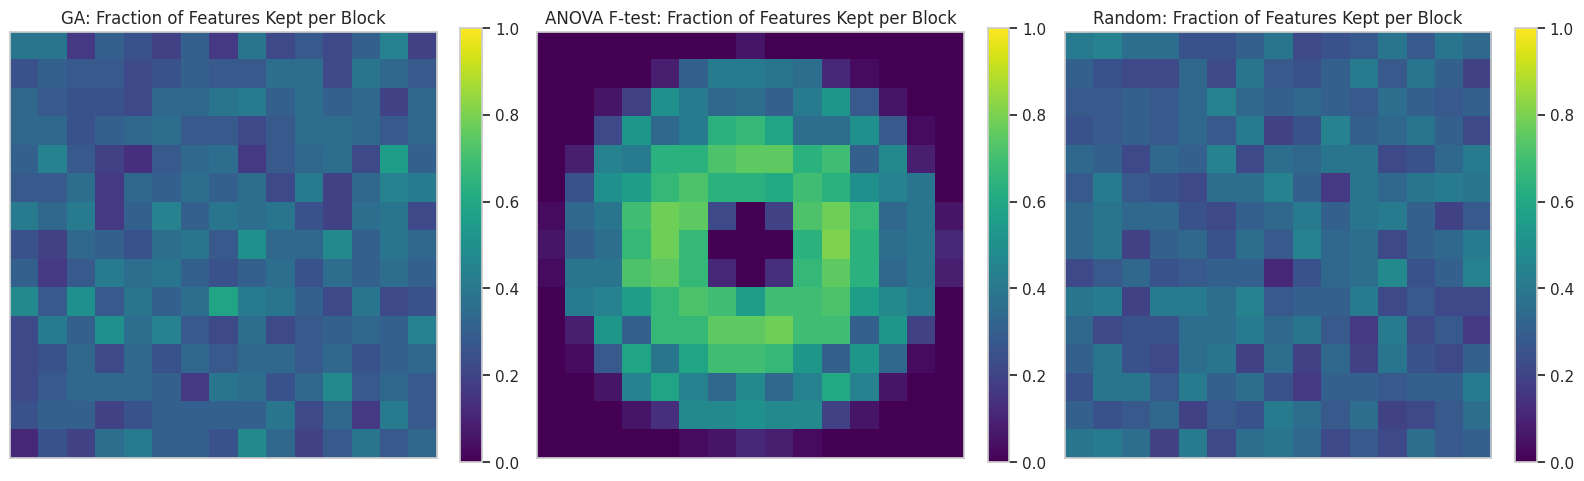

In [30]:
def block_map(idx):
    m = np.zeros(N_FEATURES, dtype=np.float32)
    m[idx] = 1
    return m.reshape(N_BLOCKS, N_BLOCKS, -1).mean(axis=-1).T

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (title, idx) in zip(axes, [("GA", ga_idx), ("ANOVA F-test", kbest_idx), ("Random", rand_idx)]):
    im = ax.imshow(block_map(idx), cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"{title}: Fraction of Features Kept per Block")
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
save_fig("bonus_spatial_heatmap.png")
plt.show()

## Bonus 3. Bootstrap Confidence Interval of Macro-F1 Difference

Mean difference: -1.351 | 95% CI: [-2.294, -0.418]


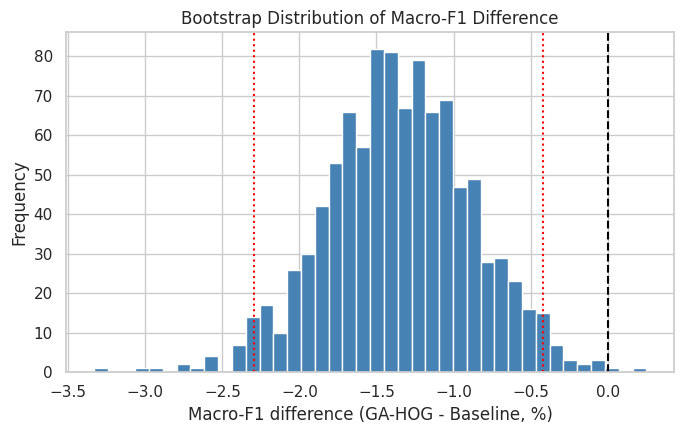

In [31]:
rng = np.random.default_rng(SEED)
n_test = len(y_test)
diffs = []
for _ in range(1000):
    i = rng.integers(0, n_test, n_test)
    diffs.append((f1_score(y_test[i], ga_pred[i], average="macro") -
                  f1_score(y_test[i], base_pred[i], average="macro")) * 100)
diffs = np.array(diffs)
ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
print(f"Mean difference: {diffs.mean():.3f} | 95% CI: [{ci_low:.3f}, {ci_high:.3f}]")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(diffs, bins=40, color="steelblue", edgecolor="white")
ax.axvline(0, color="black", linestyle="--")
ax.axvline(ci_low, color="red", linestyle=":")
ax.axvline(ci_high, color="red", linestyle=":")
ax.set_xlabel("Macro-F1 difference (GA-HOG - Baseline, %)")
ax.set_ylabel("Frequency")
ax.set_title("Bootstrap Distribution of Macro-F1 Difference")
plt.tight_layout()
save_fig("bonus_bootstrap_ci.png")
plt.show()

## Bonus 4. Selected Feature Indices

In [32]:
np.save(os.path.join(OUT_DIR, "ga_selected_feature_indices.npy"), ga_idx)
print("Saved", ga_idx.size, "selected feature indices")

Saved 2525 selected feature indices
